# Demo 3 — coded-aperture holotomography

**One** propagation distance through a 3-D object, with a gold coded aperture
in the beam, then joint recovery of **object**, **probe**, **aperture** and
**both position sets** with the Bilinear-Hessian solver.

The difference from [demo 2](02_holotomography.ipynb) is the beam, not the
sample. There, four distances give four different contrast transfer functions
and that is what makes the phase recoverable. Here there is one distance — but
the mask shifts from angle to angle, so every projection sees a different
speckle pattern, and that diversity does the same job.

The geometry is the ESRF single-coded-aperture setting taken from
`phascade/simulations/esrf_simulation/params.py`, which is the validated
simulation of this experiment. One GPU, about 2 minutes.

Everything is written out here; the notebook imports nothing but the package
itself.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') + '/src')
from types import SimpleNamespace
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
from scipy.fft import fft2, fftn, ifft2, ifftn, fftshift
import scipy.ndimage as ndimage
from mpi4py import MPI
from holotomocupy.logger_config import set_log_level

set_log_level('INFO')
comm = MPI.COMM_WORLD        # one rank here; the .py next door runs the same on N
print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Geometry

Four lengths set everything else. The one to notice is `Z_CODE`, which is
**negative**: the aperture sits upstream of the *focal spot*, not between the
focus and the sample. So the code → sample Fresnel distance comes out negative
too, and `RecCoded` has to handle that — it is the real configuration, not a
convenience.

All planes share one index grid, but each has its own physical pixel size:
342 nm at the aperture against 80 nm at the sample. That ratio is what the
next section depends on.

In [2]:
ENERGY    = 33.35                     # keV
DET_PIXEL = 3 * 1.01250442970688e-6   # NATIVE detector pixel [m]
Z_CODE    = -18e-3                    # focus -> code; NEGATIVE = upstream of the focus
Z_SAMPLE  = 4.214e-3                  # focus -> sample
Z_DET     = 1.28                      # focus -> detector

CROP      = 2048                      # full detector width [native px]
BIN = 4                               # n = CROP / 2**BIN
n        = CROP // 2**BIN
det_px   = DET_PIXEL * 2**BIN

wavelength = 1.24e-09 / ENERGY

plane_px  = lambda z: det_px * z / Z_DET          # pixel size at plane z
voxelsize = plane_px(Z_SAMPLE)
code_px   = abs(plane_px(Z_CODE))

# parallel-beam-equivalent Fresnel distances, reference plane = the sample
d1 = Z_SAMPLE**2 * (1 / Z_CODE   - 1 / Z_SAMPLE)   # code   -> sample  (negative)
d2 = Z_SAMPLE**2 * (1 / Z_SAMPLE - 1 / Z_DET)      # sample -> detector

nobj    = n + 64                      # room for the +-15 px sample displacement
scan_px = int(np.ceil(n / 8))         # per-angle code travel
q       = max(64, n // 8)
ncode   = int(np.ceil((n + 2*scan_px + 32) / q) * q)

# Smallest alias-free grid per leg: Propagation pads n -> 2n, so the guard is
# n/2 a side while Nyquist content deflects by lambda*D/(2p) px.
min_grid = {k: wavelength * abs(d) / voxelsize**2
            for k, d in (('code->sample', d1), ('sample->det', d2))}
margin = min(n / v for v in min_grid.values())

print(f'n={n}  nobj={nobj}  ncode={ncode}   code scan +-{scan_px} px')
print(f'pixel size:  code {code_px*1e9:.1f} nm   sample {voxelsize*1e9:.1f} nm'
      f'   det {det_px*1e9:.0f} nm        ratio code/sample {code_px/voxelsize:.2f}x')
print(f'D_eff:  code->sample {d1*1e3:+.4f} mm   sample->det {d2*1e3:+.4f} mm')
print(f'alias margin {margin:.1f}x  ({"clean" if margin >= 2 else "MARGINAL"})')

n=128  nobj=192  ncode=192   code scan +-16 px
pixel size:  code 683.4 nm   sample 160.0 nm   det 48600 nm        ratio code/sample 4.27x
D_eff:  code->sample -5.2005 mm   sample->det +4.2001 mm
alias margin 16.9x  (clean)


## The phantom

The same nested cube frames as demo 2: rotated off-axis so no edge lines up
with the grid, then low-passed. Edges in every direction and a wide range of
feature sizes, which is what makes it a fair test of resolution and of the
position refinement.

In [3]:
def _frame_edges(cube, p1, p2):
    """The 12 edges of the axis-aligned cube [p1, p2]^3, set to 1."""
    for a, b in ((p1, p1), (p1, p2), (p2, p1), (p2, p2)):
        cube[p1:p2, a, b] = 1
        cube[a, p1:p2, b] = 1
        cube[a, b, p1:p2] = 1


def _rotate3d(vol, ang_xy=28, ang_xz=45, order=1):
    a, b = np.deg2rad(ang_xy), np.deg2rad(ang_xz)
    Rz = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
    Ry = np.array([[np.cos(b), 0, np.sin(b)], [0, 1, 0], [-np.sin(b), 0, np.cos(b)]])
    A = np.linalg.inv(Ry @ Rz)
    c = (np.array(vol.shape) - 1) / 2.0
    return ndimage.affine_transform(vol, A, offset=c - A @ c, order=order,
                                    mode='constant', cval=0.0, prefilter=False)


def phantom3d(n, delta=1.0, beta=1e-2):
    """complex64 (n, n, n): -delta + i*beta times the phantom."""
    amps = np.array([3, -3, 1, 3, -4, 1, 4], dtype='float32')
    dil = (np.array([33, 28, 25, 21, 16, 10, 3], dtype='float32') / 256.0) * n
    ax = np.arange(-n // 2, n // 2, dtype='float32')
    x, y, z = np.meshgrid(ax, ax, ax, indexing='ij')
    r2 = x * x + y * y + z * z
    del x, y, z

    obj = np.zeros((n, n, n), dtype='float32')
    cube = np.zeros((n, n, n), dtype='float32')
    r = int(n * 0.2)
    for amp, d in zip(amps, dil):
        cube.fill(0.0)
        _frame_edges(cube, n // 2 - r // 2, n // 2 + r // 2)
        fc = fftn(fftshift(cube), workers=-1)
        fs = fftn(fftshift((r2 < d * d).astype('float32')), workers=-1)
        obj += amp * (fftshift(ifftn(fc * fs, workers=-1)).real > 1.0)

    obj = _rotate3d(obj)
    obj = np.roll(obj, (-10 * n // 256, -15 * n // 256), axis=(1, 2))
    np.maximum(obj, 0, out=obj)

    v = np.arange(-n // 2, n // 2, dtype='float32') / n
    vx, vy, vz = np.meshgrid(v, v, v, indexing='ij')
    filt = fftshift(np.exp(-3.0 * (vx**2 + vy**2 + vz**2)).astype('float32'))
    obj = ifftn(fftn(obj) * filt).real
    obj[obj < 0] = 0
    return (obj * (-delta + 1j * beta)).astype('complex64')



## The coded aperture

Random squares of gold on a 45°-rotated lattice. Three details matter, and all
three are easy to get wrong:

* **it is built on the aperture's own pixel size**, 342 nm, not the 80 nm
  sample voxel. Using the voxel would misstate the fabricated cell size by
  4.3x — a 2 µm cell would come out 25 px wide instead of 5.9.
* **the transmission is real gold**: `exp(i·k·(−δ + iβ)·t·pattern)` with δ, β
  at this energy. Contrast goes as `2|sin(φ/2)|`, so it *peaks* at the
  thickness giving π — 6.49 µm of Au at 33.35 keV. A 2 µm mask reaches only
  0.97 rad, so it is a realistic mask rather than the best possible one.
* **the lattice is hashed directly in rotated coordinates**, so rotating costs
  no interpolation, and supersampling antialiases the cell edges.

δ and β are pinned below rather than taken from `xraylib`, which is not a
dependency of this package.

In [4]:
# delta, beta for Au (19.3 g/cm^3) at 33.35 keV, from xraylib.
AU_DELTA, AU_BETA = 2.863698e-06, 1.190692e-07

def _hash_bits(iu, iv, seed):
    """Deterministic 0/1 per integer cell index (splitmix64 finalizer), so
    the pattern can be built directly in rotated coordinates."""
    u64 = np.uint64
    seed_term = u64((seed & 0xFFFFFFFF) * 0x165667B19E3779F9 % (1 << 64))
    h = (iu.astype(u64) * u64(0x9E3779B97F4A7C15)) ^ \
        (iv.astype(u64) * u64(0xC2B2AE3D27D4EB4F)) ^ seed_term
    h ^= h >> u64(30); h *= u64(0xBF58476D1CE4E5B9)
    h ^= h >> u64(27); h *= u64(0x94D049BB133111EB)
    h ^= h >> u64(31)
    return (h & u64(1)).astype(np.float32)


def code_pattern(n, feature_m, pixel_size_m, angle_deg=45.0, seed=0, supersample=2):
    """(n, n) float32 fill fraction per pixel of a random square lattice."""
    s = max(1, int(supersample))
    w = float(feature_m) / float(pixel_size_m)       # cell side, in pixels
    th = np.deg2rad(angle_deg)
    ct, st = np.cos(th), np.sin(th)
    sub = (np.arange(s, dtype=np.float64) + 0.5) / s - 0.5
    grid = np.arange(n, dtype=np.float64) - n / 2.0 + 0.5
    xs = (grid[:, None] + sub[None, :]).ravel()
    Y, X = np.meshgrid(xs, xs, indexing='ij')
    u = (X * ct + Y * st) / w
    v = (-X * st + Y * ct) / w
    bits = _hash_bits(np.floor(u).astype(np.int64), np.floor(v).astype(np.int64), seed)
    return bits.reshape(n, s, n, s).mean(axis=(1, 3)).astype(np.float32)


def coded_aperture(n, feature_m, pixel_size_m, thickness_m, energy_kev,
                   angle_deg=45.0, seed=0, supersample=2):
    """complex64 (n, n): exp(i*k*(-delta + i*beta)*t*pattern)."""
    pattern = code_pattern(n, feature_m, pixel_size_m, angle_deg, seed, supersample)
    k = 2 * np.pi / (1.24e-09 / energy_kev)
    return np.exp(1j * k * pattern * (-AU_DELTA + 1j * AU_BETA)
                  * float(thickness_m)).astype('complex64')

In [5]:
def zoom(a, f=6):
    """The central 1/f of a 2-D array: the texture, not the support ring."""
    h, w = a.shape
    dh, dw = h // (2 * f), w // (2 * f)
    return a[h // 2 - dh:h // 2 + dh, w // 2 - dw:w // 2 + dw]


def panels(items, zoom_factor=6, cmap='gray', vref=None):
    """Each item as (full frame, {f}x zoom), on one grey scale."""
    ref = vref if vref is not None else items[-1][1]
    vmin, vmax = np.percentile(ref, [0.5, 99.5])
    fig, ax = plt.subplots(2, len(items), figsize=(4.2 * len(items), 8.4),
                           squeeze=False)
    for k, (lab, img) in enumerate(items):
        ax[0][k].imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax[0][k].set_title(lab)
        ax[1][k].imshow(zoom(img, zoom_factor), cmap=cmap, vmin=vmin, vmax=vmax)
        ax[1][k].set_title(f'{lab} — {zoom_factor}x centre')
        for r in (0, 1):
            ax[r][k].axis('off')
    fig.tight_layout()


def slices(lab, v, zoom_factor=6, vref=None):
    """The three mid-planes, full and zoomed, on one grey scale."""
    panels([(f'{lab} z', v[v.shape[0] // 2].real),
            (f'{lab} y', v[:, v.shape[1] // 2].real),
            (f'{lab} x', v[:, :, v.shape[2] // 2].real)],
           zoom_factor=zoom_factor, vref=vref)

## Truth

The cell size is quoted on the **code plane**, so it stays equally well
sampled whatever `BIN` is: 5.9 pixels per cell here, which `phascade` calls
well sampled (it wants ≥ 4, and refuses below 2).

The probe is flat — a unit plane wave, as in `phascade`'s own baseline
(`PROBE_NPY = None`): the aperture is then the *only* source of illumination
diversity. Truth and starting guess are both exactly 1, so `prb` carries no
error and the demo is not asking BH to recover it; a structured probe is
demo 2's job.

object (192, 192, 192), probe (128, 128), code (192, 192)
cell 2.00 um = 2.93 code px   fill 0.494
3.0 um Au -> 1.452 rad   (t_pi = 6.49 um, where the contrast 2|sin(phi/2)| peaks)


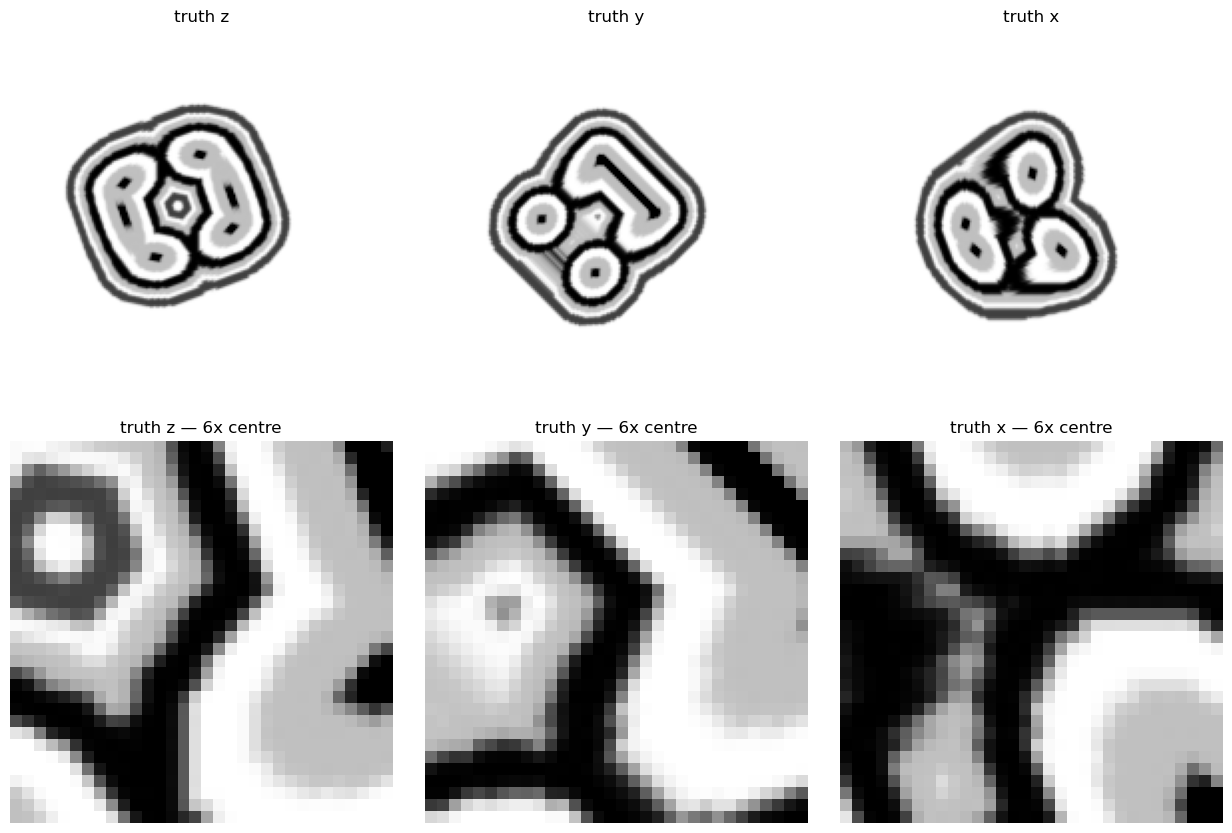

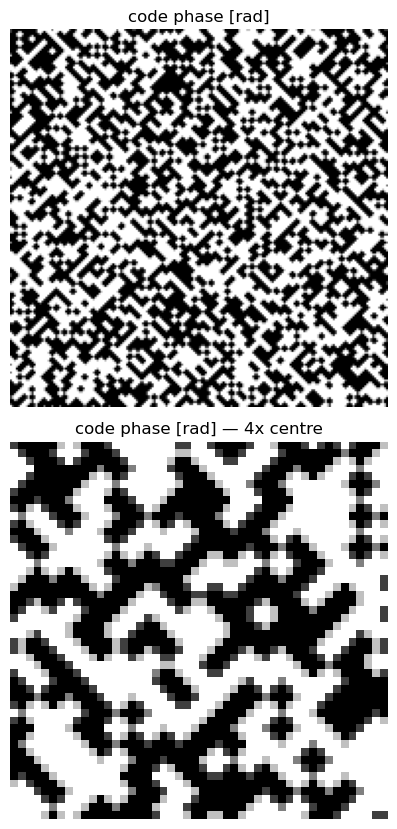

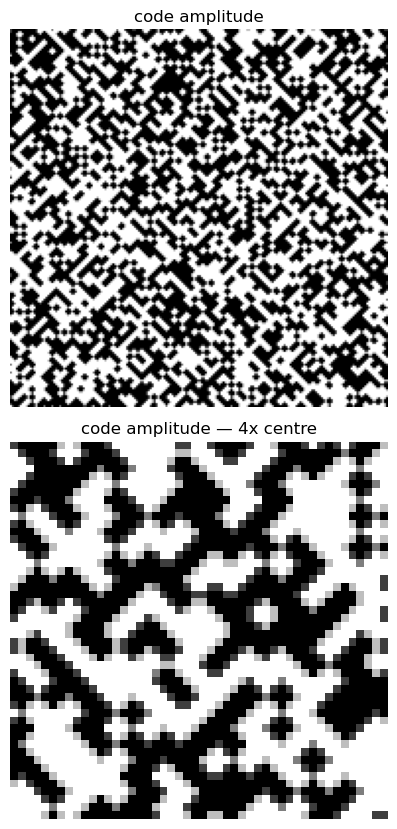

In [6]:
ntheta, niter = 360, 129
feature_m   = 1.0e-6 * 2**(BIN - 3)    # 2.0 um at BIN=3, the params.py value
thickness_m = 3.0e-6                   # Au

obj  = phantom3d(nobj)
prb  = np.ones((n, n), dtype='complex64')   # flat: see the markdown above
code = coded_aperture(ncode, feature_m, code_px, thickness_m, ENERGY)

rng = np.random.default_rng(10)
pos           = (30 * (rng.random((ntheta, 2)) - 0.5)).astype('float32')
pos_err       = (rng.random((ntheta, 2)) - 0.5).astype('float32')
pos_code      = rng.uniform(-scan_px, scan_px, (ntheta, 2)).astype('float32')
pos_code_err  = (rng.random((ntheta, 2)) - 0.5).astype('float32')
theta = np.linspace(0, np.pi, ntheta, dtype='float32')

t_pi = np.pi / (2 * np.pi / wavelength * AU_DELTA)
print(f'object {obj.shape}, probe {prb.shape}, code {code.shape}')
print(f'cell {feature_m*1e6:.2f} um = {feature_m/code_px:.2f} code px'
      f'   fill {code_pattern(ncode, feature_m, code_px).mean():.3f}')
print(f'{thickness_m*1e6:.1f} um Au -> {np.ptp(np.angle(code)):.3f} rad'
      f'   (t_pi = {t_pi*1e6:.2f} um, where the contrast 2|sin(phi/2)| peaks)')

slices('truth', obj, vref=obj[nobj // 2].real)
panels([('code phase [rad]', np.angle(code))], zoom_factor=4)
panels([('code amplitude', np.abs(code))], zoom_factor=4)

## Forward: one distance, through the aperture

`RecCoded` is the same kind of object as `Rec`, with two extra variables and
two extra cascade levels. Outermost level first:

| level | operator |
|---|---|
| F5 | `psi = S_pos(proj)` — object-plane shift |
| F4 | `exp(1j * psi)` |
| F3 | `code_s = S_pos_code(code)` — **the windowed code shift** |
| F2 | `prb_s = D_code(prb * code_s)` — **Fresnel, code plane → sample** |
| F1 | `x0 = D(prb_s * exp(1j psi))` — Fresnel, sample → detector |
| F0 | the data misfit |

`Rec` is this chain with F3 and F2 removed. `rho` gains two entries:
`[obj, prb, pos, code, pos_code]`.

In [7]:
from holotomocupy.rec_coded_mpi import RecCoded
from holotomocupy.reader_coded import CodedWriter

args = SimpleNamespace(
    energy=ENERGY, detector_pixelsize=det_px,
    focustodetectordistance=Z_DET, z1=Z_SAMPLE, z1_code=Z_CODE, theta=theta,
    ntheta=ntheta, nz=n, n=n, nzobj=nobj, nobj=nobj, ncode=ncode,
    mask=0.9, lam_laplacian=0, rho=[1, 0.05, 0.02, 0.05, 0.02],
    code_pad_frac=0.125, shift_type='fft',
    freeze_code=False, freeze_pos_code=False,
    niter=niter, nchunk=16, checkpoint_step=niter // 4,
    error_step=niter // 8, start_iter=0, comm=comm)
cl = RecCoded(args)
writer = CodedWriter(path_out='./demo_out/rec_coded', comm=comm,
                     st_obj=cl.st_obj, end_obj=cl.end_obj, nzobj=nobj, nobj=nobj,
                     st_theta=cl.st_theta, end_theta=cl.end_theta,
                     ntheta=ntheta, nz=n, n=n, ncode=ncode)

cl.vars['obj'][:]      = obj
cl.vars['prb'][:]      = prb
cl.vars['code'][:]     = cp.asarray(code)
cl.vars['pos'][:]      = pos
cl.vars['pos_code'][:] = pos_code
cl.gen_data(cl.vars, cl.data)      # INTENSITY, which is what F0 compares against

/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/conv2d_cufftdx.py:265: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  if cufftdx_available():


2026-11-05 13:40:02 [rank=0] code window: [160, 160] (pad 16, 16) out of a [192, 192] plane, code_pad_frac=0.125


### What the mask buys

The same object and probe, with and without the aperture. Without it, one
distance gives one contrast transfer function and its zeros are simply missing
from the data. The mask breaks that up — and because it moves, it breaks it up
*differently at every angle*, which is the diversity the four distances of
demo 2 provide instead.

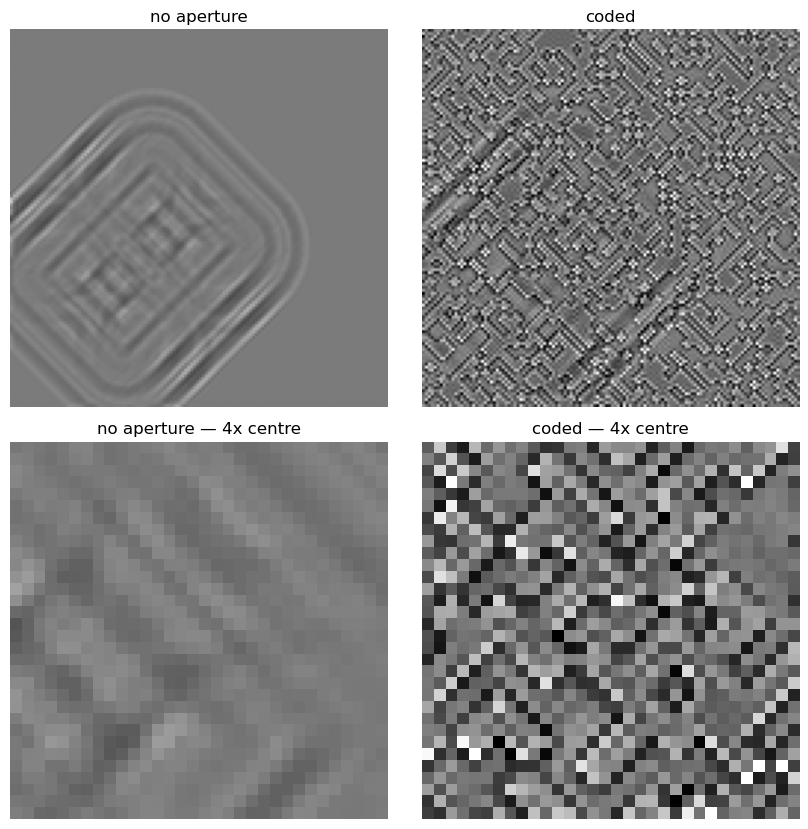

In [8]:
data_coded = cp.asnumpy(cl.data[0]).copy()

cl.vars['code'][:] = 1                  # transparent = plain holotomography
cl.gen_data(cl.vars, cl.data)
data_plain = cp.asnumpy(cl.data[0]).copy()

cl.vars['code'][:] = cp.asarray(code)   # put it back
cl.gen_data(cl.vars, cl.data)

panels([('no aperture', data_plain), ('coded', data_coded)], zoom_factor=4)

## The starting point

A real coded run calibrates the aperture first, by near-field ptychography on
the mask alone — that is what [demo 1](01_nfp_probe.ipynb) does for a probe.
So the honest start is a *measured* code, the truth plus some error, not a
flat one: solving for the mask from nothing at the same time as the object is
not how the experiment is done.

### A Paganin start, adapted to one distance

Demo 2's `multi_paganin` needs several distances only because it has to invert
several different contrast-transfer functions at once; with one distance it
reduces to the textbook single-distance Paganin formula, so the same function
works here once `data.shape[0] == 1`.

What it needs is the usual **flat field** — what the detector would see with
no sample — divided out of the data before inverting. In plain holotomography
that flat field is one fixed frame, because the probe does not move. Here it
is not fixed: the aperture shifts every angle, so the flat field is a
*different speckle pattern at every angle*. We get it from the forward model
itself, exactly as a real experiment would from a calibration scan: run the
cascade with `obj` forced to zero — identity transmission — at the TRUE
code, probe and `pos_code` for that angle. Dividing the real data by that
isolates the object's own effect on the intensity, and from there it is
single-distance Paganin + FBP, same as demo 2.

In [9]:
def multi_paganin(data, distances, wavelength, voxelsize, delta_beta, alpha=1e-2):
    """Phase from [ndist, ny, nx] flat-field-normalised intensities.

    Same function as demo 2's. With ndist=1 the sum over j has one term and
    this IS the textbook single-distance Paganin formula -- nothing here is
    coded-aperture specific."""
    fx = cp.fft.fftfreq(data.shape[-1], d=voxelsize).astype('float32')
    fy = cp.fft.fftfreq(data.shape[-2], d=voxelsize).astype('float32')
    fx, fy = cp.meshgrid(fx, fy)
    num = den = 0
    for j in range(data.shape[0]):
        taylor = 1 + wavelength * distances[j] * cp.pi * delta_beta * (fx**2 + fy**2)
        num += taylor * cp.fft.fft2(data[j].astype('complex64'))
        den += taylor**2
    num /= len(distances)
    den = den / len(distances) + alpha
    return cp.log(cp.real(cp.fft.ifft2(num / den))) * delta_beta * 0.5

In [10]:
# The per-angle flat field: code + probe only, no sample, at the TRUE
# calibration state (the code, probe, pos and pos_code are all still the
# truth here -- the perturbed starting guess is built in the NEXT cell).
# obj=0 means identity transmission, so this is exactly what gen_data()
# would write if the sample were removed from the beam.
obj_truth = cl.vars['obj'].copy()
cl.vars['obj'][:] = 0
flat = np.empty_like(cl.data)
cl.gen_data(cl.vars, flat)
cl.vars['obj'][:] = obj_truth

2026-11-05 13:40:24 [rank=0] Tomo binned scatter: tile 64x64: 36 tiles, 100% non-empty, samples/tile median 1729 max 9464, 64 subproblems (69% combining), index 0 MB, duplication 1.34x


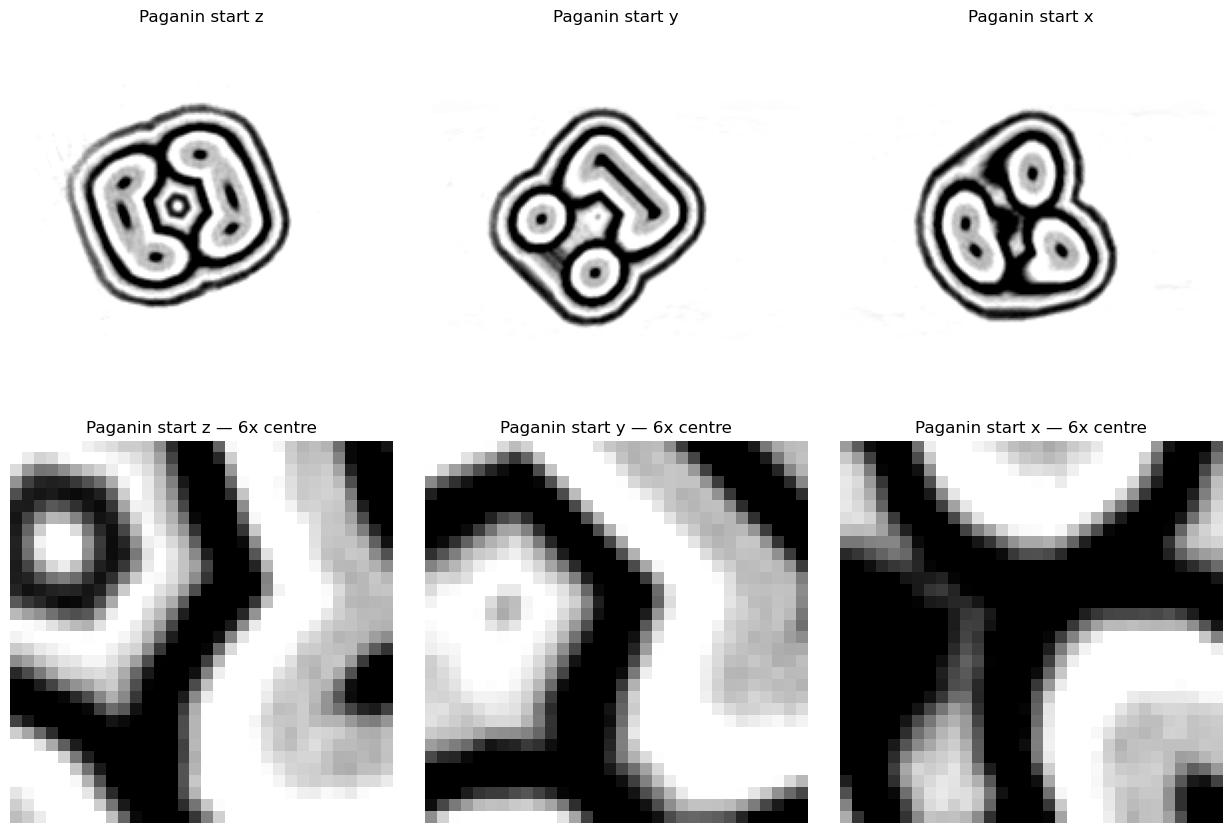

In [11]:
paganin = 100.0    # delta/beta of the phantom; matches phantom3d's default

mags = cl.cl_shift.unit_mag(1)         # m = 1: one distance, no magnification
psi = cp.zeros((ntheta, nobj, nobj), dtype='complex64')
data_c = cp.asarray(cl.data)
flat_c = cp.asarray(flat)
for i in range(ntheta):
    r = cp.asarray(cl.vars['pos'][i:i + 1])
    rdata = data_c[i:i + 1] / (flat_c[i:i + 1] + 1e-5)
    big = cp.exp(cl.cl_shift.curlySback(
        cp.log(rdata.astype('complex64')), r, mags)[0].real)
    ph = multi_paganin(big[None], cl.cl_prop.distance, cl.cl_prop.wavelength,
                       cl.cl_prop.voxelsize, paganin)
    psi[i] = ph + 1j * ph / paganin

obj0 = cp.empty((nobj, nobj, nobj), dtype='complex64')
for z in range(0, nobj, cl.nchunk):          # cl_tomo is sized for nchunk slices
    z1_ = min(z + cl.nchunk, nobj)
    obj0[z:z1_] = cl.cl_tomo.fbp(cp.ascontiguousarray(psi[:, z:z1_]), 'ramp')
obj0 = cp.asnumpy(obj0)

slices('Paganin start', obj0, vref=obj[nobj // 2].real)

In [12]:
code_err = 0.02                      # as a fraction of the code's own contrast
c = float(np.abs(code - code.mean()).std())
code0 = (code + code_err * c * (rng.standard_normal(code.shape)
                                + 1j * rng.standard_normal(code.shape))
         ).astype('complex64')

cl.vars['obj'][:]      = obj0
cl.vars['prb'][:]      = 1
cl.vars['code'][:]     = cp.asarray(code0)
cl.vars['pos'][:]      = pos + pos_err
cl.vars['pos_code'][:] = pos_code + pos_code_err

## Inverse

In [13]:
cl.BH(writer=writer)

2026-11-05 13:41:12 [rank=0] data mask: |pos|<=15.34px margin=2px -> keeps 100.0% of the pixels per angle (min 100.0%, max 100.0%). F0 still divides by the FULL ntheta*nz*n, so reported errors scale with that fraction and are not comparable with an unmasked run.
2026-11-05 13:41:12 [rank=0] Initial err=1.31381e-02 
2026-11-05 13:41:12 [rank=0] iter=0: 0.7732sec (-min=0.7285sec) err=4.74224e-03 |dobj|^2=6.93799e+02 rel=1.339e-02
2026-11-05 13:41:13 [rank=0] Writer: checkpoint saved → ./demo_out/rec_coded/checkpoints/checkpoint_0000.h5
2026-11-05 13:41:13 [rank=0] Writer: mid-slice TIFF saved → ./demo_out/rec_coded/checkpoints_tiff/checkpoint_0000_obj_re.tiff
2026-11-05 13:41:13 [rank=0] Writer: vertical-slice TIFF saved → ./demo_out/rec_coded/checkpoints_tiff/checkpoint_0000_obj_re_vert.tiff
2026-11-05 13:41:13 [rank=0] iter=0: pos abs error [px]  d0: y=(0.0004±0.0003 max=0.0025)  x=(0.0006±0.0004 max=0.0025)
2026-11-05 13:41:13 [rank=0] pos error plot → ./demo_out/rec_coded/pos_errors/

{'obj': array([[[-9.41824049e-12-8.75940650e-13j,
           2.72689961e-11+1.81842371e-11j,
           4.87901872e-11+1.49656763e-11j, ...,
           6.44381373e-15-1.87894041e-11j,
          -4.94094392e-12-4.66513148e-11j,
          -3.72773904e-12-2.52828818e-13j],
         [-4.53399228e-11-9.89143316e-12j,
           2.47034880e-12+7.68464459e-12j,
           8.12420964e-12+1.20695814e-11j, ...,
           7.97869409e-12-6.31612332e-11j,
          -2.44651816e-11+2.06415822e-11j,
          -1.86478541e-11+6.08791975e-11j],
         [-5.77857250e-12+2.60095244e-11j,
          -2.00031797e-11-5.87830002e-12j,
          -1.93244639e-11+3.07877226e-12j, ...,
          -7.19815700e-12+4.37143594e-12j,
           1.30122855e-13+2.95041075e-11j,
           4.27938848e-12-3.47705588e-12j],
         ...,
         [-1.13388101e-11-5.70804645e-12j,
          -1.80073977e-11+3.17025503e-11j,
           5.22697961e-11+7.54449767e-11j, ...,
           2.71669024e-11+4.15071102e-12j,
          

In [14]:
rec = np.asarray(cl.vars['obj'])
code_got = cp.asnumpy(cl.vars['code'])


def corr(a, b):
    a = a.ravel() - a.mean()
    b = b.ravel() - b.mean()
    return float(np.abs(np.vdot(a, b)) / (np.linalg.norm(a) * np.linalg.norm(b)))


# Inside the solver's own circular mask: outside it the reconstruction is zero
# by construction, and scoring that region only measures the mask.
yy, xx, _ = np.mgrid[0:nobj, 0:nobj, 0:nobj] - (nobj - 1) / 2
m = (yy**2 + xx**2) < (0.9 * nobj / 2)**2
print(f'object correlation with the truth {corr(rec.real[m], obj.real[m]):.4f}')
print(f'code   correlation with the truth {corr(code_got, code):.4f}'
      f'  (started at {corr(code0, code):.4f})')

# The `pos abs error` logged during BH is measured from the STARTING guess, so
# it grows as the refinement works. These are the distances to the truth.
print(f'pos      error {np.abs(np.asarray(cl.vars["pos"]) - pos).mean():.4f} px,'
      f' from {np.abs(pos_err).mean():.4f}')
print(f'pos_code error {np.abs(np.asarray(cl.vars["pos_code"]) - pos_code).mean():.4f} px,'
      f' from {np.abs(pos_code_err).mean():.4f}')

object correlation with the truth 0.9846
code   correlation with the truth 0.9999  (started at 1.0000)
pos      error 0.0612 px, from 0.2594
pos_code error 0.0006 px, from 0.2413


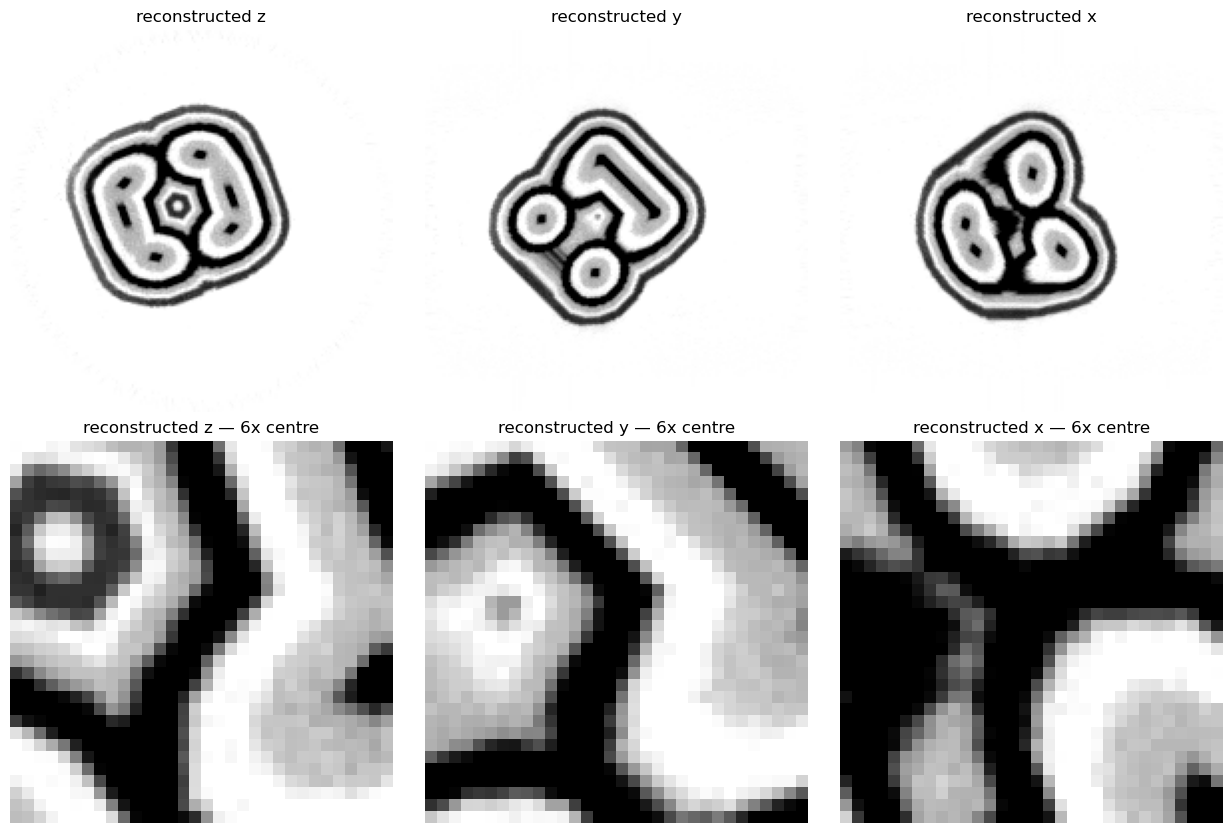

In [15]:
slices('reconstructed', rec, vref=obj[nobj // 2].real)

Checkpoints, mid-slice TIFFs, the position-error plots for both `pos` and
`pos_code`, and `conv.csv` are in `demo_out/rec_coded/`.

The script next door, [`03_coded_holotomography.py`](03_coded_holotomography.py),
is this notebook with the parameters moved to `argparse` and MPI left in, and
it imports the same builders from [`phantoms.py`](phantoms.py).